# SoilGrids maps from a latitude / longitude
### Generated in part with the help of SI

Enter a coordinate and this notebook will, for **soil pH**, **soil organic carbon** and **bulk density**:

1. build a bounding box around it (2° wide by default),
2. download only that box from the **ISRIC SoilGrids** web service,
3. convert the stored integers to real units (pH; g/kg; kg/dm³) and draw a map,
4. report the value at your exact point and save a summary CSV.

**How to use:** run the cells from top to bottom. The settings cell asks for longitude and latitude.
Data: ISRIC SoilGrids, CC BY 4.0 (https://soilgrids.org).

## 1. Install (first run only)
Skip this cell if the libraries are already installed.

In [ ]:
%pip install -q requests rasterio numpy matplotlib pandas

## 2. Functions
Run once. Nothing to edit here.

In [1]:
import csv
import os
import re
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import requests
from IPython.display import Image, display
from matplotlib.colors import BoundaryNorm, ListedColormap


In [2]:
# ------------------------------- settings ---------------------------------
WCS_URL = "https://maps.isric.org/mapserv"
CRS_4326 = "http://www.opengis.net/def/crs/EPSG/0/4326"
DEPTHS = ("0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm")
STATS = ("mean", "Q0.05", "Q0.5", "Q0.95")      # real predictions (not the uncertainty layer)
TIFF_MAGIC = (b"II*\x00", b"MM\x00*", b"II+\x00", b"MM\x00+")

# Conventional soil-pH classes (colour per class), acid -> alkaline
PH_BREAKS = [3.5, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.5]
PH_COLORS = ["#a50026", "#d73027", "#f46d43", "#fdae61", "#fee08b",
             "#d9ef8b", "#a6d96a", "#66bd63", "#1a9850", "#2c7fb8"]

# scale = multiply the stored integer by this to get the real unit
# valid = physically plausible range, used only to warn about a wrong scale
PROPERTIES = {
    "phh2o": {"label": "Soil pH (water)", "unit": "pH", "scale": 0.1,
              "map": "/map/phh2o.map", "classes": (PH_BREAKS, PH_COLORS),
              "valid": (0, 14), "decimals": 1},
    "soc":   {"label": "Soil organic carbon", "unit": "g/kg", "scale": 0.1,
              "map": "/map/soc.map", "cmap": "YlOrBr",
              "valid": (0, 700), "decimals": 1},
    "bdod":  {"label": "Bulk density (fine earth)", "unit": "kg/dm³", "scale": 0.01,
              "map": "/map/bdod.map", "cmap": "cividis_r",
              "valid": (0.05, 2.5), "decimals": 2},
}
DEFAULT_PROPS = ("phh2o", "soc", "bdod")
# ---------------------------------------------------------------------------


def open_image(path):
    """Open a PNG in the computer's default image viewer (best effort)."""
    path = str(Path(path).resolve())
    try:
        if sys.platform.startswith("win"):
            os.startfile(path)                          # Windows
        elif sys.platform == "darwin":
            subprocess.Popen(["open", path])            # macOS
        else:
            subprocess.Popen(["xdg-open", path])        # Linux
    except Exception as e:
        print(f"(Could not open the image automatically: {e})\nIt is saved at: {path}")


# ---------------------------- bounding box + download -----------------------
def make_bbox(lon, lat, width_deg=2.0):
    """(west, south, east, north) in degrees, centred on the point."""
    if not (-180 <= lon <= 180 and -90 <= lat <= 90):
        raise ValueError("Longitude must be -180..180 and latitude -90..90.")
    half = width_deg / 2.0
    west, east = lon - half, lon + half
    south, north = lat - half, lat + half
    if west < -180 or east > 180 or south < -90 or north > 90:
        print("Note: box clipped at the edge of the world (-180..180, -90..90).")
    return (max(west, -180.0), max(south, -90.0), min(east, 180.0), min(north, 90.0))


def _base_params(prop, request, coverage_id=None):
    p = [("map", PROPERTIES[prop]["map"]), ("SERVICE", "WCS"),
         ("VERSION", "2.0.1"), ("REQUEST", request)]
    if coverage_id:
        p.append(("COVERAGEID", coverage_id))
    return p


def detect_axis_labels(prop, coverage_id, timeout=60):
    """Ask the service what it calls the lat/lon axes (e.g. 'Lat' / 'Long')."""
    try:
        r = requests.get(WCS_URL, params=_base_params(prop, "DescribeCoverage", coverage_id),
                         timeout=timeout)
        m = re.search(r'axisLabels="([^"]+)"', r.text)
        if m:
            lat = lon = None
            for lbl in m.group(1).split():
                low = lbl.lower()
                if low.startswith("lat") or low == "y":
                    lat = lbl
                elif low.startswith("lon") or low == "x":
                    lon = lbl
            if lat and lon:
                return lat, lon
    except requests.RequestException:
        pass
    return None


def download_tif(prop, bbox, coverage_id, out_path, timeout=300):
    """GetCoverage for the bbox; saves a GeoTIFF and returns its path."""
    west, south, east, north = bbox
    candidates = []
    detected = detect_axis_labels(prop, coverage_id)
    if detected:
        candidates.append(detected)
    candidates += [c for c in (("Lat", "Long"), ("lat", "lon"), ("Y", "X")) if c not in candidates]

    first_problem = None
    for lat_lbl, lon_lbl in candidates:
        params = _base_params(prop, "GetCoverage", coverage_id) + [
            ("FORMAT", "GEOTIFF_INT16"),
            ("SUBSET", f"{lon_lbl}({west},{east})"),
            ("SUBSET", f"{lat_lbl}({south},{north})"),
            ("SUBSETTINGCRS", CRS_4326),
            ("OUTPUTCRS", CRS_4326),
        ]
        r = requests.get(WCS_URL, params=params, timeout=timeout)
        if r.ok and r.content[:4] in TIFF_MAGIC:
            Path(out_path).write_bytes(r.content)
            return Path(out_path)
        if first_problem is None:   # the first attempt uses the best-known axis names
            first_problem = f"HTTP {r.status_code}: {r.text[:300].strip()}"
    raise RuntimeError("SoilGrids WCS did not return a GeoTIFF "
                       "(no data for this box, bad coverage name, or service down).\n"
                       f"Service response: {first_problem}")


# ------------------------------ reading + stats -----------------------------
def read_layer(path, scale, nodata=None, max_pixels=2500):
    """Return (array in real units with NaN for no-data, extent, crs).

    No-data (the file's nodata value, or anything <= 0) is masked BEFORE any
    downsampling, and block averages use only valid pixels.
    """
    with rasterio.open(path) as src:
        raw = src.read(1).astype("float64")
        nd = src.nodata if nodata is None else nodata
        nd = 0 if nd is None else nd
        arr = raw * scale
        arr[(raw == nd) | (raw <= 0)] = np.nan
        b = src.bounds
        extent = (b.left, b.right, b.bottom, b.top)
        crs = src.crs

    f = max(1, int(np.ceil(max(arr.shape) / max_pixels)))
    if f > 1:
        h, w = (arr.shape[0] // f) * f, (arr.shape[1] // f) * f
        blocks = arr[:h, :w].reshape(h // f, f, w // f, f)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            arr = np.nanmean(blocks, axis=(1, 3))
        res_x = (extent[1] - extent[0]) / raw.shape[1]
        res_y = (extent[3] - extent[2]) / raw.shape[0]
        extent = (extent[0], extent[0] + w * res_x, extent[3] - h * res_y, extent[3])
    return arr, extent, crs


def write_float_geotiff(path_in, path_out, scale, description):
    """Full-resolution float32 GeoTIFF in real units (NaN = no data)."""
    with rasterio.open(path_in) as src:
        raw = src.read(1).astype("float32")
        nd = 0 if src.nodata is None else src.nodata
        arr = raw * np.float32(scale)
        arr[(raw == nd) | (raw <= 0)] = np.nan
        profile = src.profile
        profile.update(dtype="float32", nodata=np.nan, compress="deflate", count=1)
        with rasterio.open(path_out, "w", **profile) as dst:
            dst.write(arr, 1)
            dst.set_band_description(1, description)


def value_at_point(tif, lon, lat, scale):
    """Value at the exact coordinates in real units, or None if no data there."""
    with rasterio.open(tif) as src:
        try:
            row, col = src.index(lon, lat)
            if not (0 <= row < src.height and 0 <= col < src.width):
                return None
            raw = float(src.read(1)[row, col])
        except Exception:
            return None
        nd = src.nodata
    if raw <= 0 or (nd is not None and raw == nd):
        return None
    return raw * scale


# ---------------------------------- plotting --------------------------------
def plot_map(arr, extent, png, title, prop, point=None):
    """Draw the map for one property and save it as a PNG."""
    cfg = PROPERTIES[prop]
    fig, ax = plt.subplots(figsize=(10, 9))

    if "classes" in cfg:                       # classified colours (pH)
        breaks, colors = cfg["classes"]
        cmap = ListedColormap(colors)
        cmap.set_bad("#cfd8dc")
        im = ax.imshow(arr, extent=extent, origin="upper", cmap=cmap,
                       norm=BoundaryNorm(breaks, cmap.N), interpolation="nearest")
        cbar = fig.colorbar(im, ax=ax, ticks=breaks, shrink=0.8, pad=0.02)
    else:                                      # continuous colours, robust 2-98% stretch
        valid = arr[np.isfinite(arr)]
        vmin, vmax = np.percentile(valid, [2, 98])
        if vmin == vmax:
            vmin, vmax = vmin - 0.5, vmax + 0.5
        cmap = plt.get_cmap(cfg["cmap"]).copy()
        cmap.set_bad("#cfd8dc")
        im = ax.imshow(arr, extent=extent, origin="upper", cmap=cmap,
                       vmin=vmin, vmax=vmax, interpolation="nearest")
        cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02, extend="both")
    cbar.set_label(f"{cfg['label']} ({cfg['unit']})")

    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    ax.set_title(title)
    ax.set_aspect(1 / np.cos(np.radians((extent[2] + extent[3]) / 2)))
    ax.grid(True, color="white", alpha=0.3, linewidth=0.5)
    if point:
        lon, lat = point
        ax.plot(lon, lat, marker="*", markersize=16, markerfacecolor="white",
                markeredgecolor="black", linestyle="none", label=f"{lon:.3f}, {lat:.3f}")
        ax.legend(loc="upper right")
    fig.tight_layout()
    fig.savefig(png, dpi=150)
    plt.close(fig)


# ---------------------------------- pipeline --------------------------------
def process_property(prop, lon, lat, bbox, depth, stat, out, show=False):
    """Download, convert, map and summarise one property. Returns a result dict."""
    cfg = PROPERTIES[prop]
    coverage_id = f"{prop}_{depth}_{stat}"
    tag = f"{prop}_{depth}_{stat}_lon{lon}_lat{lat}"

    print(f"\n--- {cfg['label']} ({coverage_id}) ---")
    raw_tif = download_tif(prop, bbox, coverage_id, out / f"{tag}_raw.tif")
    with rasterio.open(raw_tif) as src:
        print(f"Downloaded {src.width} x {src.height} pixels, CRS {src.crs}")

    arr, extent, _ = read_layer(raw_tif, cfg["scale"])
    valid = arr[np.isfinite(arr)]
    if valid.size == 0:
        raise RuntimeError("No valid pixels in this box (water or masked land).")
    lo, hi = cfg["valid"]
    if valid.min() < lo or valid.max() > hi:
        print(f"WARNING: values {valid.min():.2f} to {valid.max():.2f} {cfg['unit']} are "
              f"outside the expected {lo}-{hi}. Check the scale factor.")

    d = cfg["decimals"]
    print(f"Range {valid.min():.{d}f} to {valid.max():.{d}f} {cfg['unit']}, "
          f"mean {valid.mean():.{d}f}, median {np.median(valid):.{d}f}; "
          f"no-data {100 * np.isnan(arr).mean():.1f}%")

    png = out / f"{tag}.png"
    float_tif = out / f"{tag}_converted.tif"
    plot_map(arr, extent, png, f"{cfg['label']} ({depth}, {stat})", prop, point=(lon, lat))
    write_float_geotiff(raw_tif, float_tif, cfg["scale"], f"{cfg['label']} ({cfg['unit']})")

    at_point = value_at_point(raw_tif, lon, lat, cfg["scale"])
    if at_point is None:
        print(f"Value at ({lon}, {lat}): no data at that pixel (water or masked land)")
    else:
        print(f"Value at ({lon}, {lat}): {at_point:.{d}f} {cfg['unit']}")
    print(f"Map image: {png.resolve()}")
    if show:
        open_image(png)

    return {"property": prop, "label": cfg["label"], "unit": cfg["unit"],
            "depth": depth, "stat": stat,
            "min": float(valid.min()), "mean": float(valid.mean()),
            "median": float(np.median(valid)), "max": float(valid.max()),
            "pct_no_data": float(100 * np.isnan(arr).mean()),
            "value_at_point": at_point,
            "raw_tif": raw_tif, "png": png, "converted_tif": float_tif}


def run(lon, lat, props=DEFAULT_PROPS, width_deg=2.0, depth="0-5cm", stat="mean",
        out_dir="soilgrids_output", show=False):
    """Full pipeline for one or more properties.

    Returns {"results": [one dict per property], "errors": {property: message},
             "summary_csv": path or None}.
    One property failing does not stop the others.
    """
    props = list(props)
    for p in props:
        if p not in PROPERTIES:
            raise ValueError(f"Unknown property {p!r}; choose from {list(PROPERTIES)}")
    if depth not in DEPTHS:
        raise ValueError(f"depth must be one of {DEPTHS}")
    if stat not in STATS:
        raise ValueError(f"stat must be one of {STATS}")

    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    bbox = make_bbox(lon, lat, width_deg)
    print(f"Bounding box (W, S, E, N): {tuple(round(v, 4) for v in bbox)}")

    results, errors = [], {}
    for prop in props:
        try:
            results.append(process_property(prop, lon, lat, bbox, depth, stat, out, show))
        except Exception as e:
            errors[prop] = str(e)
            print(f"\n!! {prop} failed: {e}")

    summary_csv = None
    if results:
        summary_csv = out / f"summary_{depth}_{stat}_lon{lon}_lat{lat}.csv"
        cols = ["property", "label", "unit", "depth", "stat", "request_lon", "request_lat",
                "value_at_point", "min", "mean", "median", "max", "pct_no_data"]
        with open(summary_csv, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=cols)
            w.writeheader()
            for r in results:
                row = {k: r.get(k) for k in cols}
                row["request_lon"], row["request_lat"] = lon, lat
                for k in ("value_at_point", "min", "mean", "median", "max", "pct_no_data"):
                    if row[k] is not None:
                        row[k] = round(row[k], 4)
                w.writerow(row)
        print(f"\nSummary: {summary_csv.resolve()}")
    if errors:
        print(f"Failed properties: {', '.join(errors)}")
    return {"results": results, "errors": errors, "summary_csv": summary_csv}


## 3. Choose a location and settings

In [3]:
# ---------------- settings: edit these ----------------
lon = float(input("Longitude: "))     # e.g. 46    (east is positive)
lat = float(input("Latitude: "))      # e.g. 59    (north is positive)

props = ["phh2o", "soc", "bdod"]   # pH, soil organic carbon, bulk density (remove any you don't need)
width_deg = 2.0          # box width in degrees, centred on the point
depth = "0-5cm"          # 0-5cm, 5-15cm, 15-30cm, 30-60cm, 60-100cm, 100-200cm
stat = "mean"            # mean, Q0.05, Q0.5, Q0.95
out_dir = "soilgrids_output"   # folder for downloads, maps and the summary CSV


## 4. Download, map, and summarise

Bounding box (W, S, E, N): (60.2275, 41.6484, 62.2275, 43.6484)

--- Soil pH (water) (phh2o_0-5cm_mean) ---
Downloaded 885 x 837 pixels, CRS EPSG:4326
Range 7.4 to 8.1 pH, mean 7.7, median 7.7; no-data 1.1%
Value at (61.2275, 42.6484): 7.8 pH
Map image: C:\Users\bertr\VSCODE\InterSESHllar\earthaccess_pull\soilgrids_output\phh2o_0-5cm_mean_lon61.2275_lat42.6484.png

--- Soil organic carbon (soc_0-5cm_mean) ---
Downloaded 885 x 837 pixels, CRS EPSG:4326
Range 6.4 to 85.2 g/kg, mean 15.7, median 14.5; no-data 1.1%
Value at (61.2275, 42.6484): 24.3 g/kg
Map image: C:\Users\bertr\VSCODE\InterSESHllar\earthaccess_pull\soilgrids_output\soc_0-5cm_mean_lon61.2275_lat42.6484.png

--- Bulk density (fine earth) (bdod_0-5cm_mean) ---
Downloaded 885 x 837 pixels, CRS EPSG:4326
Range 1.28 to 1.51 kg/dm³, mean 1.43, median 1.43; no-data 1.1%
Value at (61.2275, 42.6484): 1.41 kg/dm³
Map image: C:\Users\bertr\VSCODE\InterSESHllar\earthaccess_pull\soilgrids_output\bdod_0-5cm_mean_lon61.2275_lat42.6484.pn

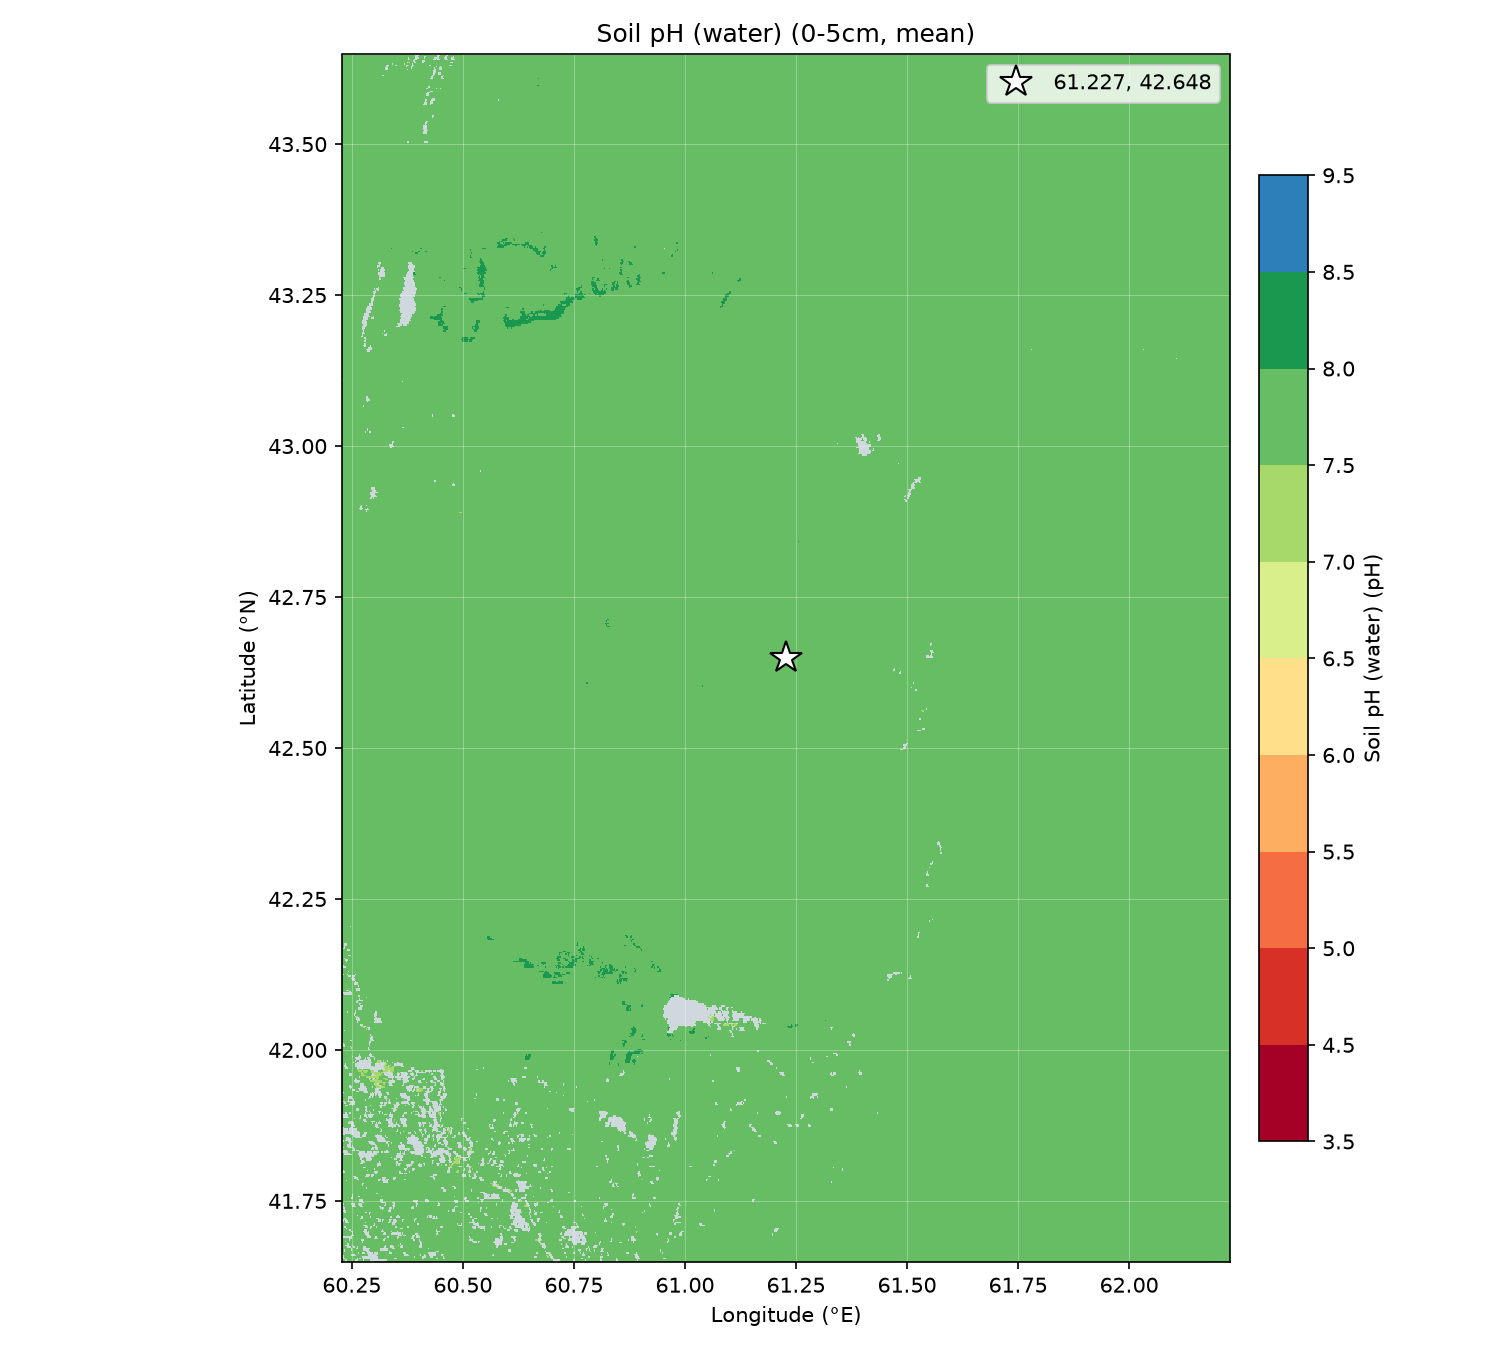

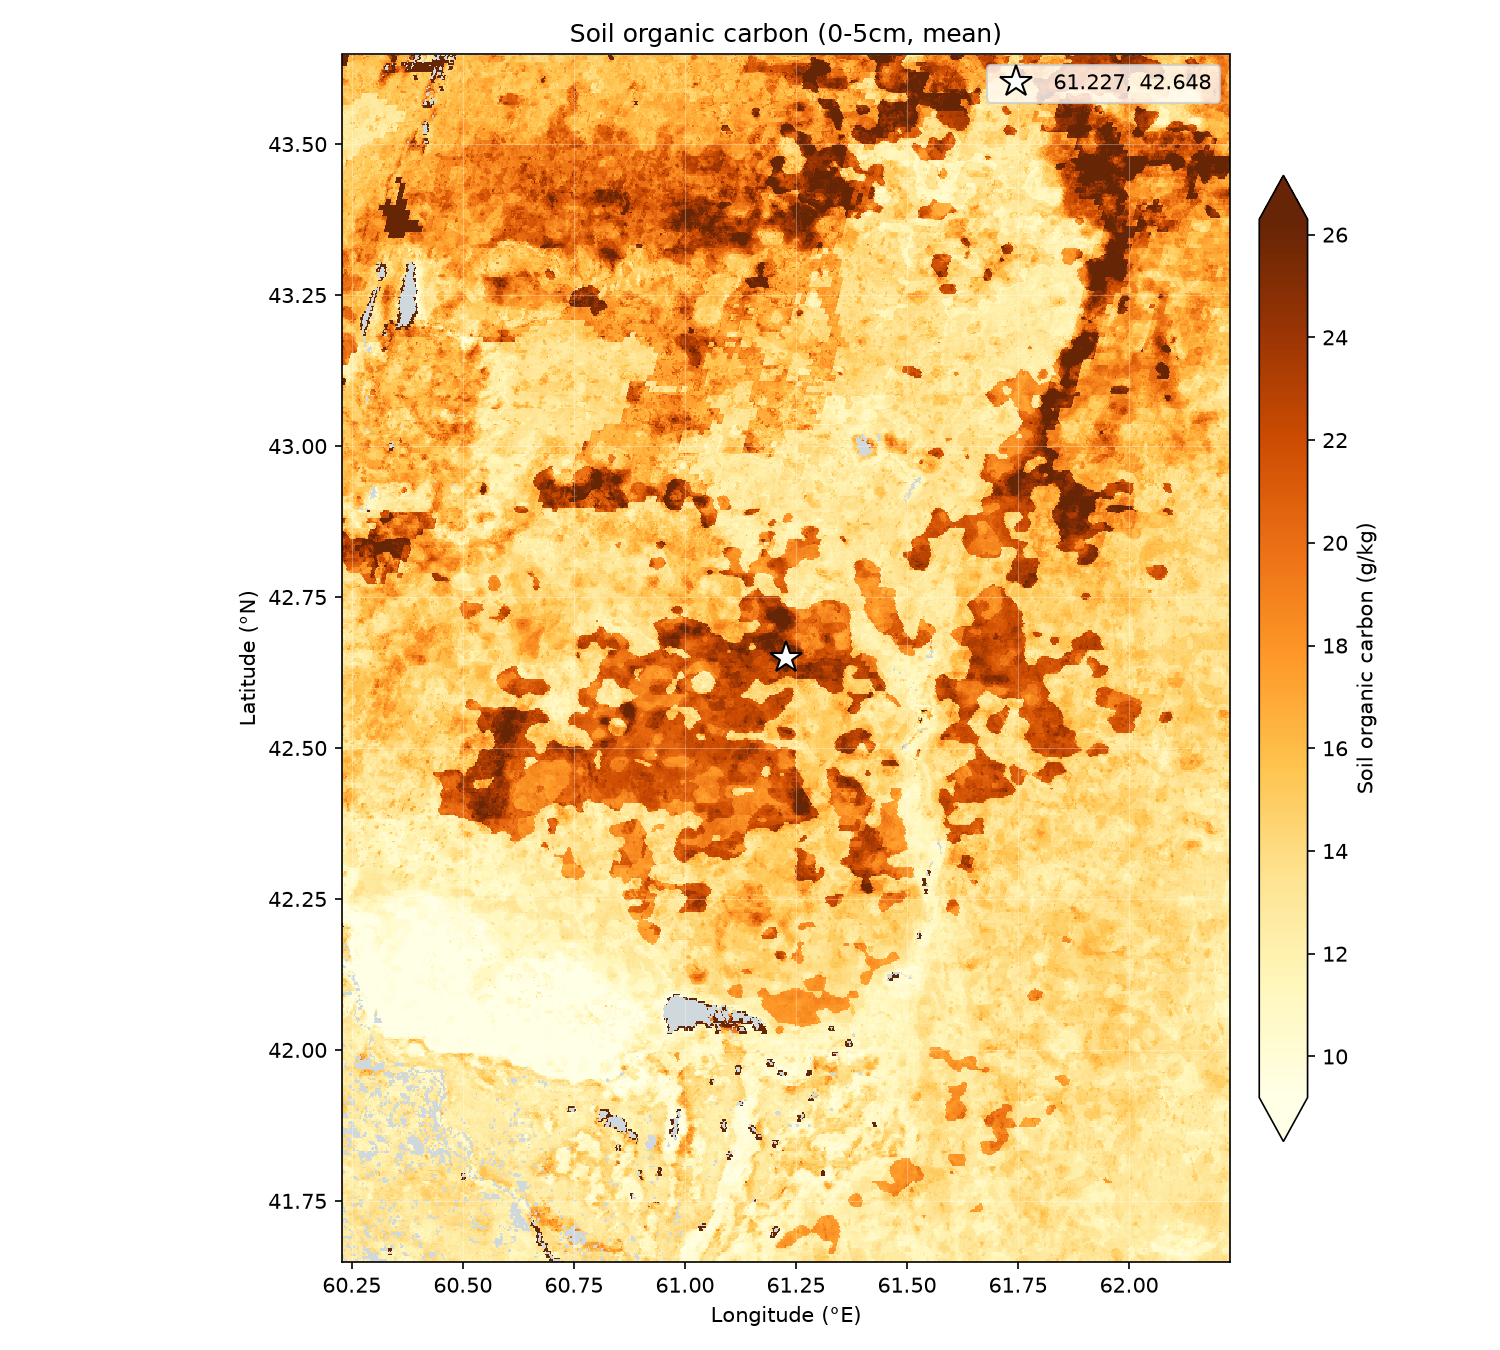

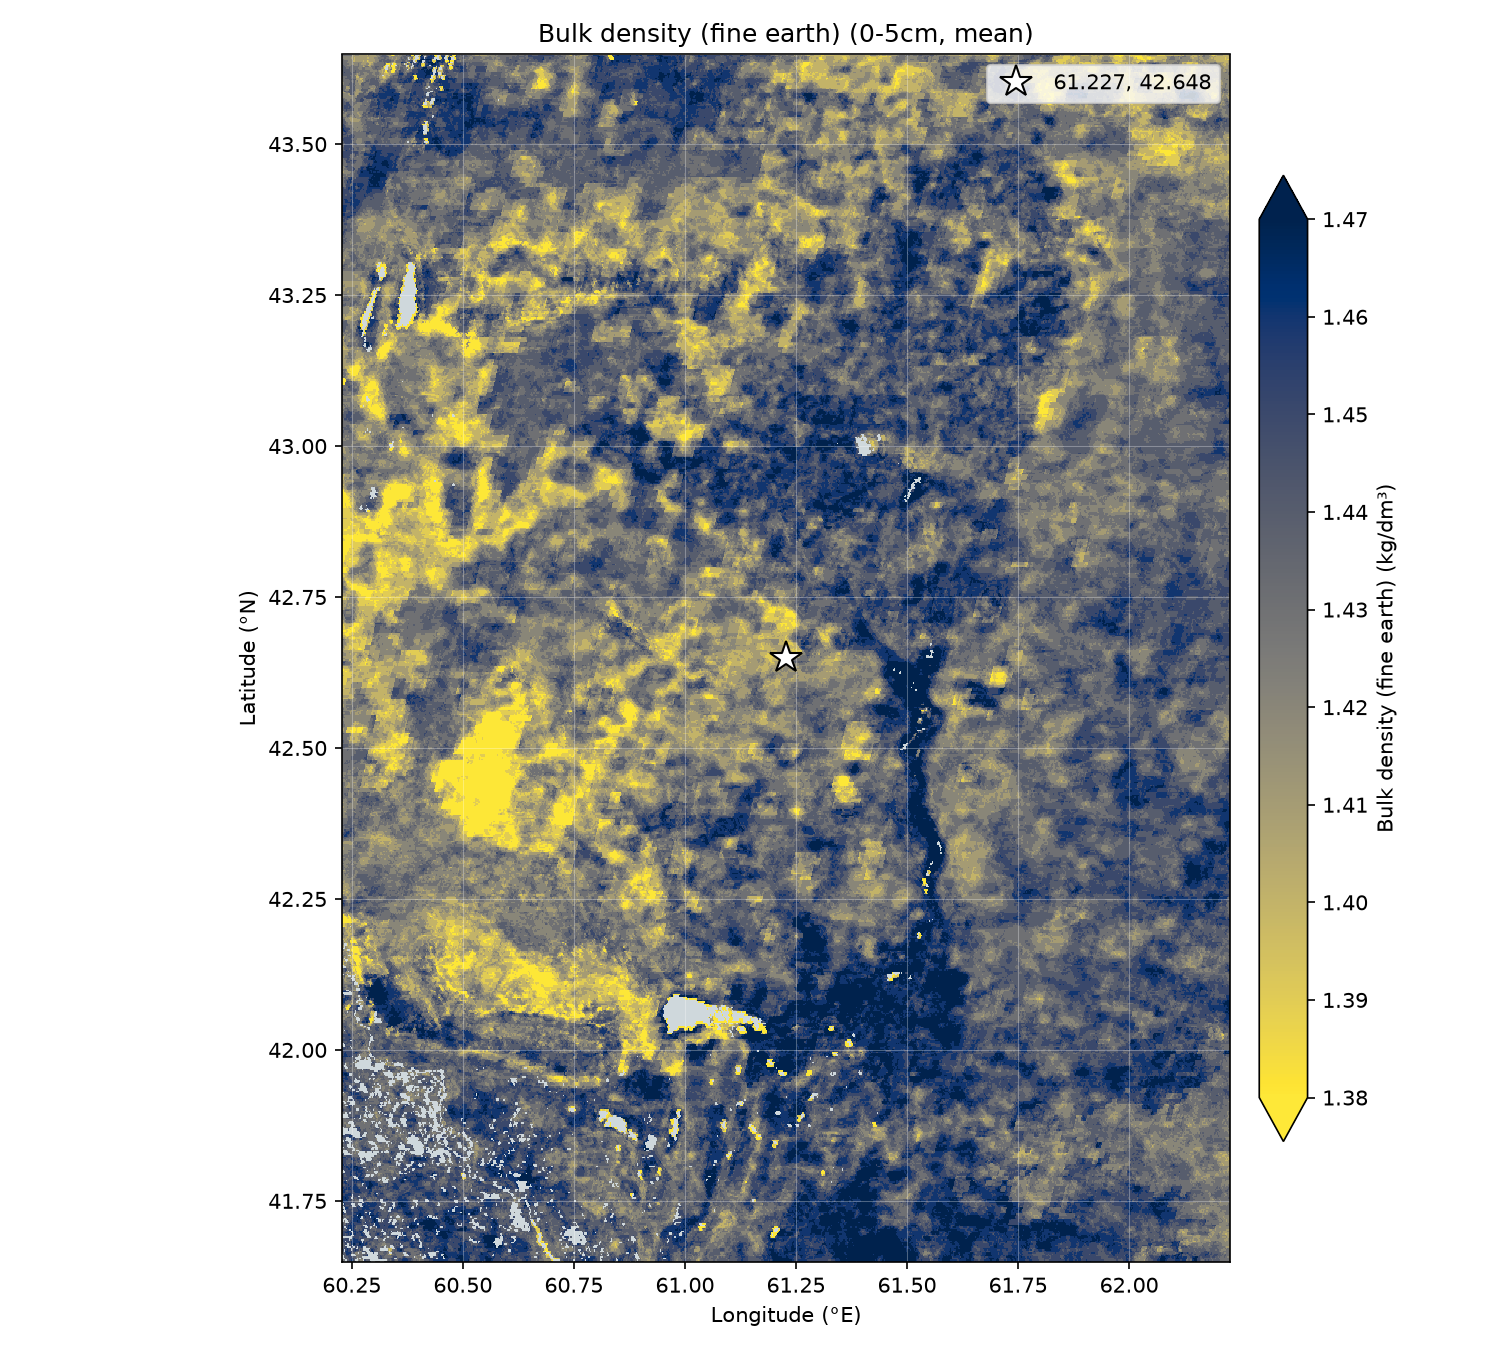


Summary (also saved to soilgrids_output\summary_0-5cm_mean_lon61.2275_lat42.6484.csv )


,property,label,unit,depth,stat,request_lon,request_lat,value_at_point,min,mean,median,max,pct_no_data
0,phh2o,Soil pH (water),pH,0-5cm,mean,61.2275,42.6484,7.80,7.40,7.7135,7.70,8.10,1.1382
1,soc,Soil organic carbon,g/kg,0-5cm,mean,61.2275,42.6484,24.30,6.40,15.6757,14.50,85.20,1.1382
2,bdod,Bulk density (fine earth),kg/dm³,0-5cm,mean,61.2275,42.6484,1.41,1.28,1.4323,1.43,1.51,1.1382


In [4]:
out = run(lon, lat, props=props, width_deg=width_deg, depth=depth, stat=stat, out_dir=out_dir)

for r in out["results"]:
    display(Image(filename=str(r["png"]), width=650))

if out["summary_csv"]:
    print("\nSummary (also saved to", out["summary_csv"], ")")
    display(pd.read_csv(out["summary_csv"]))

if out["errors"]:
    print("\nThese properties failed:")
    for k, v in out["errors"].items():
        print(f"  {k}: {v}")


In [5]:
from geojson_exporter import (
    export_soilgrids_to_geojson,
    export_emit_point_to_geojson,
)

# Example: Exporting with a custom filename directed to your OpenSpace asset folder
export_soilgrids_to_geojson(
    lon=-105.27, lat=40.01, results=my_results, filename="boulder_soil_data.geojson"
)

NameError: name 'my_results' is not defined